<a href="https://colab.research.google.com/github/rohinibanerjee87-creator/BookMyShow-MOVIE-MANAGEMENT/blob/main/Deep_Learning_Based_Human_Activity_Recognition_and_Fall_Detection_Using_BiLSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch [1/15] Train Loss: 0.1197 | Validation Loss: 0.0644
Epoch [2/15] Train Loss: 0.0278 | Validation Loss: 0.0625
Epoch [3/15] Train Loss: 0.0154 | Validation Loss: 0.0513
Epoch [4/15] Train Loss: 0.0080 | Validation Loss: 0.0509
Epoch [5/15] Train Loss: 0.0076 | Validation Loss: 0.0467
Epoch [6/15] Train Loss: 0.0123 | Validation Loss: 0.0368
Epoch [7/15] Train Loss: 0.0113 | Validation Loss: 0.0693
Epoch [8/15] Train Loss: 0.0050 | Validation Loss: 0.0584
Epoch [9/15] Train Loss: 0.0053 | Validation Loss: 0.0352
Epoch [10/15] Train Loss: 0.0065 | Validation Loss: 0.0432
Epoch [11/15] Train Loss: 0.0153 | Validation Loss: 0.0557
Epoch [12/15] Train Loss: 0.0089 | Validation Loss: 0.0486
Epoch [13/15] Train Loss: 0.0054 | Validation Loss: 0.0520
Epoch [14/15] Train Loss: 0.0048 | Validation Loss: 0.0437
Epoch [15/15] Train Loss: 0.0055 | Validation Loss: 0.0666
                precision    recall  f1-score   support

ADL / Non-fall       1.00      0.99      1.00      2629
          F

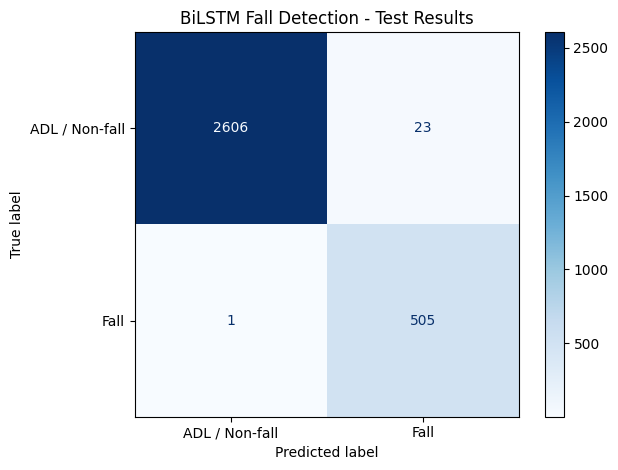

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

SEQ_LEN, EPOCHS, BATCH = 50, 15, 32
features = ["ACC1 x-axis (g)", "ACC1 y-axis (g)", "ACC1 z-axis (g)",
            "GYR1 x-axis (deg/s)", "GYR1 y-axis (deg/s)", "GYR1 z-axis (deg/s)"]

df = pd.read_csv("sensor_preprocessed (1).csv")
df["label"] = df["Group"].map({"ADL": 0, "Fall": 1})
df = df.dropna(subset=features + ["label", "Source_File", "Sample_No"]).copy()
df["label"] = df["label"].astype(int)

tr_idx, tmp_idx = next(GroupShuffleSplit(1, test_size=0.30, random_state=1).split(df, groups=df["Source_File"]))
train, temp = df.iloc[tr_idx].copy(), df.iloc[tmp_idx].copy()
v_idx, te_idx = next(GroupShuffleSplit(1, test_size=2/3, random_state=1).split(temp, groups=temp["Source_File"]))
val, test = temp.iloc[v_idx].copy(), temp.iloc[te_idx].copy()

scaler = StandardScaler()
train[features] = scaler.fit_transform(train[features])
val[features] = scaler.transform(val[features])
test[features] = scaler.transform(test[features])

def create_sequences(frame):
    X, y = [], []
    for _, part in frame.groupby("Source_File", sort=False):
        part = part.sort_values("Sample_No")
        xv = part[features].to_numpy(np.float32)
        yv = part["label"].to_numpy(np.int64)
        for s in range(len(part) - SEQ_LEN + 1):
            X.append(xv[s:s + SEQ_LEN])
            y.append(int(yv[s:s + SEQ_LEN].mean() >= 0.5))
    return np.asarray(X, np.float32), np.asarray(y, np.int64)

X_train, y_train = create_sequences(train)
X_val, y_val = create_sequences(val)
X_test, y_test = create_sequences(test)

if min(len(y_train), len(y_val), len(y_test)) == 0:
    raise ValueError("A data split has no complete sequences.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(X), torch.tensor(y))
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle)

train_loader = loader(X_train, y_train, True)
val_loader = loader(X_val, y_val, False)
test_loader = loader(X_test, y_test, False)

class BiLSTMModel(nn.Module):
    def __init__(self, input_size=6, hidden_size=64, num_layers=2, num_classes=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True,
                            bidirectional=True, dropout=0.3 if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        out = torch.cat((h_n[-2], h_n[-1]), dim=1)
        return self.fc(self.dropout(out))

model = BiLSTMModel().to(device)

counts = np.bincount(y_train, minlength=2)
if np.any(counts == 0):
    raise ValueError("Training sequences must contain both ADL and Fall classes.")
weights = torch.tensor(len(y_train) / (2.0 * counts), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def run_epoch(dl, train=False):
    model.train(train)
    total = 0.0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            loss = criterion(model(x), y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
    return total / len(dl.dataset)

best_val, best_state = float("inf"), None
for epoch in range(EPOCHS):
    tr_loss = run_epoch(train_loader, True)
    v_loss = run_epoch(val_loader)
    if v_loss < best_val:
        best_val = v_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f"Epoch [{epoch + 1}/{EPOCHS}] Train Loss: {tr_loss:.4f} | Validation Loss: {v_loss:.4f}")

model.load_state_dict(best_state)
model.eval()

actual, predicted = [], []
with torch.no_grad():
    for x, y in test_loader:
        predicted.extend(model(x.to(device)).argmax(1).cpu().numpy())
        actual.extend(y.numpy())

names = ["ADL / Non-fall", "Fall"]
print(classification_report(actual, predicted, labels=[0, 1], target_names=names, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(actual, predicted, labels=[0, 1]),
                       display_labels=names).plot(cmap="Blues", values_format="d")
plt.title("BiLSTM Fall Detection - Test Results")
plt.tight_layout()
plt.show()

Epoch [1/15] Train Loss: 0.3215 | Validation Loss: 0.2307
Epoch [2/15] Train Loss: 0.1838 | Validation Loss: 0.1706
Epoch [3/15] Train Loss: 0.1456 | Validation Loss: 0.0827
Epoch [4/15] Train Loss: 0.1274 | Validation Loss: 0.2302
Epoch [5/15] Train Loss: 0.1220 | Validation Loss: 0.1510
Epoch [6/15] Train Loss: 0.1043 | Validation Loss: 0.1966
Epoch [7/15] Train Loss: 0.1004 | Validation Loss: 0.1049
Epoch [8/15] Train Loss: 0.0950 | Validation Loss: 0.1340
Epoch [9/15] Train Loss: 0.0852 | Validation Loss: 0.1145
Epoch [10/15] Train Loss: 0.0816 | Validation Loss: 0.1123
Epoch [11/15] Train Loss: 0.0772 | Validation Loss: 0.1824
Epoch [12/15] Train Loss: 0.0739 | Validation Loss: 0.1142
Epoch [13/15] Train Loss: 0.0707 | Validation Loss: 0.2216
Epoch [14/15] Train Loss: 0.0630 | Validation Loss: 0.1316
Epoch [15/15] Train Loss: 0.0642 | Validation Loss: 0.1148
                precision    recall  f1-score   support

ADL / Non-fall       0.99      0.97      0.98     49852
          F

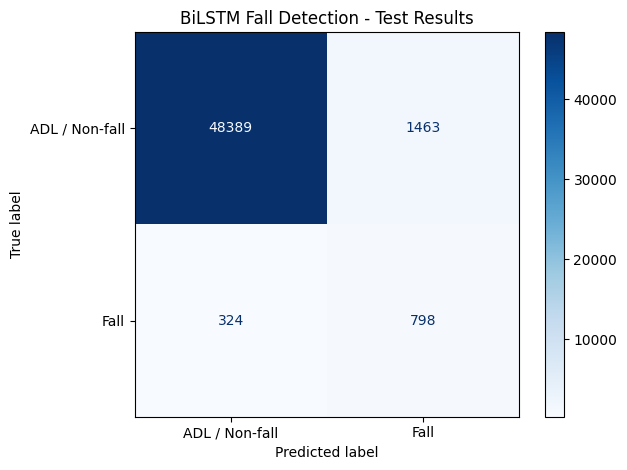

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

SEQ_LEN, EPOCHS, BATCH = 50, 15, 32
features = ["Wrist ACC x-axis (g)","Wrist ACC y-axis (g)","Wrist ACC z-axis (g)"]

df = pd.read_csv("upfall_wrist_acc.csv")
df["label"] = df["Group"].map({"ADL": 0, "Fall": 1})
df = df.dropna(subset=features + ["label", "Source_File", "Sample_No"]).copy()
df["label"] = df["label"].astype(int)

tr_idx, tmp_idx = next(GroupShuffleSplit(1, test_size=0.30, random_state=1).split(df, groups=df["Source_File"]))
train, temp = df.iloc[tr_idx].copy(), df.iloc[tmp_idx].copy()
v_idx, te_idx = next(GroupShuffleSplit(1, test_size=2/3, random_state=1).split(temp, groups=temp["Source_File"]))
val, test = temp.iloc[v_idx].copy(), temp.iloc[te_idx].copy()

scaler = StandardScaler()
train[features] = scaler.fit_transform(train[features])
val[features] = scaler.transform(val[features])
test[features] = scaler.transform(test[features])

def create_sequences(frame):
    X, y = [], []
    for _, part in frame.groupby("Source_File", sort=False):
        part = part.sort_values("Sample_No")
        xv = part[features].to_numpy(np.float32)
        yv = part["label"].to_numpy(np.int64)
        for s in range(len(part) - SEQ_LEN + 1):
            X.append(xv[s:s + SEQ_LEN])
            y.append(int(yv[s:s + SEQ_LEN].mean() >= 0.5))
    return np.asarray(X, np.float32), np.asarray(y, np.int64)

X_train, y_train = create_sequences(train)
X_val, y_val = create_sequences(val)
X_test, y_test = create_sequences(test)

if min(len(y_train), len(y_val), len(y_test)) == 0:
    raise ValueError("A data split has no complete sequences.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(X), torch.tensor(y))
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle)

train_loader = loader(X_train, y_train, True)
val_loader = loader(X_val, y_val, False)
test_loader = loader(X_test, y_test, False)

class BiLSTMModel(nn.Module):
    def __init__(self, input_size=6, hidden_size=64, num_layers=2, num_classes=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True,
                            bidirectional=True, dropout=0.3 if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        out = torch.cat((h_n[-2], h_n[-1]), dim=1)
        return self.fc(self.dropout(out))

model = BiLSTMModel(input_size=len(features)).to(device)

counts = np.bincount(y_train, minlength=2)
if np.any(counts == 0):
    raise ValueError("Training sequences must contain both ADL and Fall classes.")
weights = torch.tensor(len(y_train) / (2.0 * counts), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def run_epoch(dl, train=False):
    model.train(train)
    total = 0.0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            loss = criterion(model(x), y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
    return total / len(dl.dataset)

best_val, best_state = float("inf"), None
for epoch in range(EPOCHS):
    tr_loss = run_epoch(train_loader, True)
    v_loss = run_epoch(val_loader)
    if v_loss < best_val:
        best_val = v_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f"Epoch [{epoch + 1}/{EPOCHS}] Train Loss: {tr_loss:.4f} | Validation Loss: {v_loss:.4f}")

model.load_state_dict(best_state)
model.eval()

actual, predicted = [], []
with torch.no_grad():
    for x, y in test_loader:
        predicted.extend(model(x.to(device)).argmax(1).cpu().numpy())
        actual.extend(y.numpy())

names = ["ADL / Non-fall", "Fall"]
print(classification_report(actual, predicted, labels=[0, 1], target_names=names, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(actual, predicted, labels=[0, 1]),
                       display_labels=names).plot(cmap="Blues", values_format="d")
plt.title("BiLSTM Fall Detection - Test Results")
plt.tight_layout()
plt.show()

Epoch [1/15] Train Loss: 0.5139 | Validation Loss: 0.1434
Epoch [2/15] Train Loss: 0.1490 | Validation Loss: 0.1059
Epoch [3/15] Train Loss: 0.0864 | Validation Loss: 0.0817
Epoch [4/15] Train Loss: 0.0584 | Validation Loss: 0.0720
Epoch [5/15] Train Loss: 0.0454 | Validation Loss: 0.0762
Epoch [6/15] Train Loss: 0.0392 | Validation Loss: 0.0670
Epoch [7/15] Train Loss: 0.0297 | Validation Loss: 0.0668
Epoch [8/15] Train Loss: 0.0249 | Validation Loss: 0.0820
Epoch [9/15] Train Loss: 0.0241 | Validation Loss: 0.0600
Epoch [10/15] Train Loss: 0.0193 | Validation Loss: 0.0582
Epoch [11/15] Train Loss: 0.0173 | Validation Loss: 0.0691
Epoch [12/15] Train Loss: 0.0159 | Validation Loss: 0.0700
Epoch [13/15] Train Loss: 0.0147 | Validation Loss: 0.0784
Epoch [14/15] Train Loss: 0.0135 | Validation Loss: 0.0699
Epoch [15/15] Train Loss: 0.0139 | Validation Loss: 0.0738
              precision    recall  f1-score   support

 standing_up       0.95      0.93      0.94      4182
  getting_up   

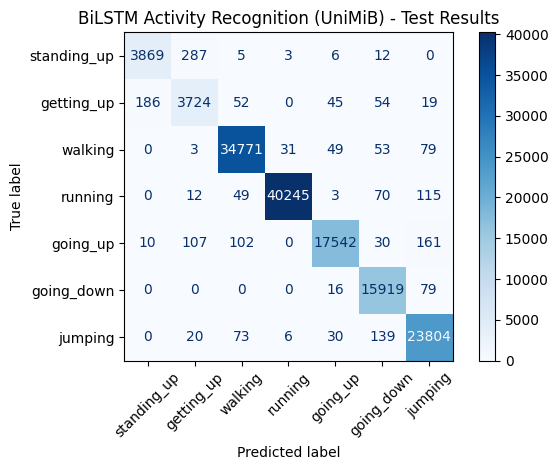

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

SEQ_LEN, EPOCHS, BATCH = 50, 15, 32
features = ["ACC1 x-axis (g)", "ACC1 y-axis (g)", "ACC1 z-axis (g)"]

# Class_ID 1..7 -> label 0..6
id_to_name = {1: "standing_up", 2: "getting_up", 3: "walking", 4: "running",
              5: "going_up", 6: "going_down", 7: "jumping"}
names = [id_to_name[i] for i in range(1, 8)]
NUM_CLASSES = len(names)

df = pd.read_csv("unimib_all8_preprocessed.csv")
df["label"] = df["Class_ID"] - 1
df = df.dropna(subset=features + ["label", "Source_File", "Sample_No"]).copy()
df["label"] = df["label"].astype(int)

tr_idx, tmp_idx = next(GroupShuffleSplit(1, test_size=0.30, random_state=1).split(df, groups=df["Source_File"]))
train, temp = df.iloc[tr_idx].copy(), df.iloc[tmp_idx].copy()
v_idx, te_idx = next(GroupShuffleSplit(1, test_size=2/3, random_state=1).split(temp, groups=temp["Source_File"]))
val, test = temp.iloc[v_idx].copy(), temp.iloc[te_idx].copy()

scaler = StandardScaler()
train[features] = scaler.fit_transform(train[features])
val[features] = scaler.transform(val[features])
test[features] = scaler.transform(test[features])

def create_sequences(frame):
    X, y = [], []
    for _, part in frame.groupby("Source_File", sort=False):
        part = part.sort_values("Sample_No")
        xv = part[features].to_numpy(np.float32)
        yv = part["label"].to_numpy(np.int64)
        for s in range(len(part) - SEQ_LEN + 1):
            X.append(xv[s:s + SEQ_LEN])
            y.append(np.bincount(yv[s:s + SEQ_LEN], minlength=NUM_CLASSES).argmax())  # majority class
    return np.asarray(X, np.float32), np.asarray(y, np.int64)

X_train, y_train = create_sequences(train)
X_val, y_val = create_sequences(val)
X_test, y_test = create_sequences(test)

if min(len(y_train), len(y_val), len(y_test)) == 0:
    raise ValueError("A data split has no complete sequences.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(X), torch.tensor(y))
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle)

train_loader = loader(X_train, y_train, True)
val_loader = loader(X_val, y_val, False)
test_loader = loader(X_test, y_test, False)

class BiLSTMModel(nn.Module):
    def __init__(self, input_size=3, hidden_size=64, num_layers=2, num_classes=NUM_CLASSES):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True,
                            bidirectional=True, dropout=0.3 if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        out = torch.cat((h_n[-2], h_n[-1]), dim=1)
        return self.fc(self.dropout(out))

model = BiLSTMModel(input_size=len(features)).to(device)

counts = np.bincount(y_train, minlength=NUM_CLASSES)
if np.any(counts == 0):
    raise ValueError("Training sequences must contain all activity classes.")
weights = torch.tensor(len(y_train) / (NUM_CLASSES * counts), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def run_epoch(dl, train=False):
    model.train(train)
    total = 0.0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            loss = criterion(model(x), y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
    return total / len(dl.dataset)

best_val, best_state = float("inf"), None
for epoch in range(EPOCHS):
    tr_loss = run_epoch(train_loader, True)
    v_loss = run_epoch(val_loader)
    if v_loss < best_val:
        best_val = v_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f"Epoch [{epoch + 1}/{EPOCHS}] Train Loss: {tr_loss:.4f} | Validation Loss: {v_loss:.4f}")

model.load_state_dict(best_state)
model.eval()

actual, predicted = [], []
with torch.no_grad():
    for x, y in test_loader:
        predicted.extend(model(x.to(device)).argmax(1).cpu().numpy())
        actual.extend(y.numpy())

labels = list(range(NUM_CLASSES))
print(classification_report(actual, predicted, labels=labels, target_names=names, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(actual, predicted, labels=labels),
                       display_labels=names).plot(cmap="Blues", values_format="d", xticks_rotation=45)
plt.title("BiLSTM Activity Recognition (UniMiB) - Test Results")
plt.tight_layout()
plt.show()